# 03 · Modelo — probabilidade de atraso

Árvore de decisão rasa (`src/dataco/model.py`), treinada só com o que se sabe no momento do pedido: modo de envio, hora, dia da semana, tipo de pagamento, mercado e segmento.

- **Unidade:** um pedido enviado. Cancelados ficam fora porque nunca são entregues.
- **Treino × teste por tempo:** treino com pedidos antes de 2017-07-01, teste depois.
- **Baseline:** taxa histórica de atraso por modo de envio.
- **Métricas:** AUC (separa atrasados de não atrasados; 0,5 = acaso, 1 = perfeito) e Brier (erro médio da probabilidade; menor é melhor).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import plot_tree

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from dataco.transform import load_dataco
from dataco.model import train

pd.set_option('display.float_format', '{:,.3f}'.format)
df = load_dataco()
result = train(df)
result['n_train'], result['n_test']

(49826, 13071)

## 1. Desempenho no período de teste

In [2]:
result['metrics']

,AUC,Brier
baseline (modo de envio),0.746,0.187
árvore (5 folhas),0.777,0.173


## 2. A árvore

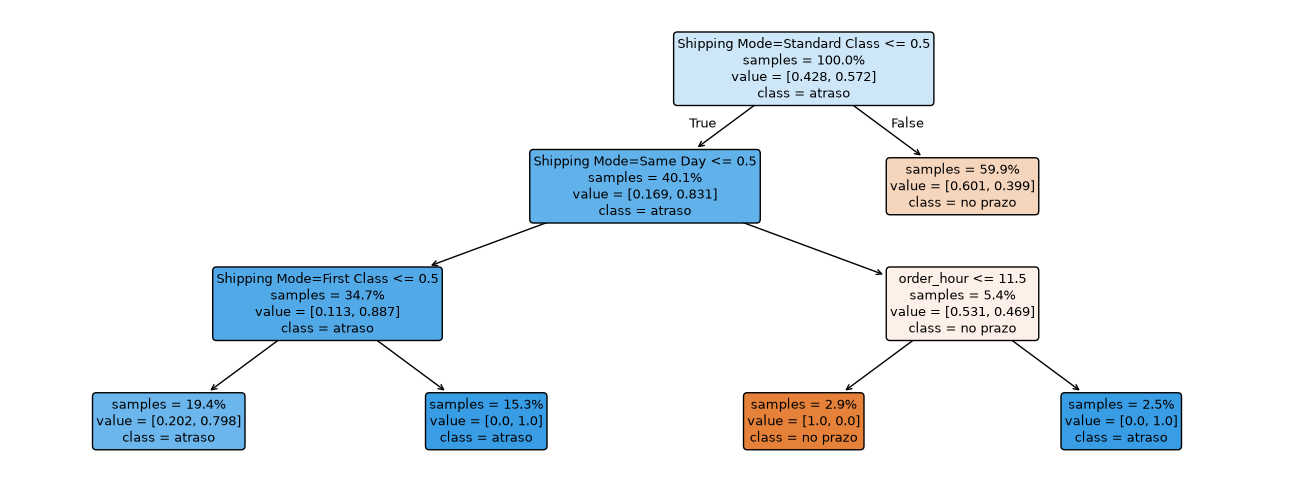

In [3]:
fig, ax = plt.subplots(figsize=(13, 5))
plot_tree(result['tree'], feature_names=result['features'], class_names=['no prazo', 'atraso'],
          filled=True, proportion=True, impurity=False, rounded=True, fontsize=9, ax=ax)
fig.tight_layout();

In [4]:
print(result['rules'])

|--- Shipping Mode=Standard Class <= 0.50
|   |--- Shipping Mode=Same Day <= 0.50
|   |   |--- Shipping Mode=First Class <= 0.50
|   |   |   |--- weights: [1950.00, 7720.00] class: True
|   |   |--- Shipping Mode=First Class >  0.50
|   |   |   |--- weights: [0.00, 7628.00] class: True
|   |--- Shipping Mode=Same Day >  0.50
|   |   |--- order_hour <= 11.50
|   |   |   |--- weights: [1422.00, 0.00] class: False
|   |   |--- order_hour >  11.50
|   |   |   |--- weights: [0.00, 1254.00] class: True
|--- Shipping Mode=Standard Class >  0.50
|   |--- weights: [17930.00, 11922.00] class: False



## 3. Calibração — a probabilidade prevista bate com o que aconteceu?

Uma linha por folha: `p_prevista` vem do treino e `taxa_real` é o observado no teste.

In [5]:
result['calibration']

,pedidos,p_prevista,taxa_real
folha,,,
3,2586,0.798,0.805
4,1974,1.000,1.000
6,337,0.000,0.000
7,394,1.000,1.000
8,7780,0.399,0.395


## 4. Comparação: árvore sem poda

Sem `min_impurity_decrease`, a árvore divide o Standard Class por mercado e tipo de pagamento. Essas divisões mudam o atraso em poucos pontos e quase não melhoram o AUC.

In [6]:
full = train(df, min_impurity_decrease=0)
pd.concat([result['metrics'], full['metrics'].iloc[1:]])

,AUC,Brier
baseline (modo de envio),0.746,0.187
árvore (5 folhas),0.777,0.173
árvore (8 folhas),0.781,0.173


## Leitura

- A probabilidade de atraso é definida pelo modo de envio e, no Same Day, pela hora do pedido.
- Outras variáveis conhecidas no pedido não acrescentam sinal útil.
- Dentro do Second e do Standard Class, o atraso parece aleatório: nenhum modelo com estes dados passa das taxas por modo.